<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="44"/>

# The Yangtze heatwave of August 2022 🌡️
### Copernicus Climate Change Service · ERA5-Land · free account

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/china/heat_era5land.ipynb)

In August 2022 a long heatwave and drought sat over the Yangtze basin. This notebook asks how much warmer than
usual the month was: the **ERA5-Land** monthly mean 2 m temperature for August 2022, minus the average of the thirty
Augusts from 1991 to 2020. ERA5-Land is the Copernicus land reanalysis at about 9 km that ECMWF produces for the
European Union; it covers land only, so the sea stays blank.

**What you need:** a Google account (to use Colab) and a free Copernicus account (step below). Everything runs on Google's computers, so a slow or mobile connection is fine.

| Data | What this notebook uses | Licence |
|---|---|---|
| [ERA5-Land monthly means](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-land-monthly-means), 0.1° | 2 m temperature, August, 1991–2020 and 2022 | Copernicus licence, free |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools for weather and climate data.

*Press **Runtime → Run all**. The data store queues requests, so step 2 can take a few minutes.*

> Not an official ECMWF product: a worked example for the ECMWF liaison visit to China, 2026. "Yangtze basin" here is a box,
> 27–33°N and 103–122°E, land points only: not the hydrological basin.

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes a few minutes the first time.
%pip install -q "earthkit-data[cds]" earthkit-plots

## Your free Copernicus key

Copernicus data is free and open, but the data stores ask you to register once so they can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (the same login works for the
   Atmosphere Data Store).
2. Open the [dataset page](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-land-monthly-means?tab=download) on the Climate Data Store and accept its licence (bottom of the Download tab). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.

**Use your own key.** Everyone who runs this notebook needs their own free Copernicus account and key. The next cell asks
for it in a hidden box and saves it on the machine running the notebook (in Colab that is a temporary machine, wiped when
you close the tab). The key is never stored in the notebook, so don't paste it into a code cell, and don't share a notebook
or screenshot that shows it. On your own computer with `~/.cdsapirc` / `~/.adsapirc` already in place, the cell asks nothing.

In [2]:
import os
from getpass import getpass
rc = {"~/.cdsapirc": "https://cds.climate.copernicus.eu/api", "~/.adsapirc": "https://ads.atmosphere.copernicus.eu/api"}
missing = [p for p in rc if not os.path.exists(os.path.expanduser(p))]
if missing:
    key = getpass("Copernicus API key: ")
    for p in missing:
        with open(os.path.expanduser(p), "w") as f:
            f.write(f"url: {rc[p]}\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import calendar
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs, cartopy.feature as cfeature
import matplotlib.patheffects as pe
from matplotlib.patches import Rectangle
import numpy as np

## 1 · Choose the month and the area

In [4]:
AREA  = [54, 73, 18, 135]                    # north, west, south, east
YEAR, MONTH = 2022, "08"
BOX   = dict(north=33, south=27, west=103, east=122)    # the "Yangtze basin" box
CITIES = [("Chengdu", 30.66, 104.07), ("Chongqing", 29.56, 106.55), ("Wuhan", 30.59, 114.31),
          ("Shanghai", 31.23, 121.47), ("Beijing", 39.90, 116.40)]
def label(ax, places):
    for name, la, lo in places:
        ax.plot(lo, la, "o", ms=6, color="#ffd23f", mec="#1a1a1a", mew=0.8, zorder=10, transform=ccrs.PlateCarree())
        ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Get ERA5-Land monthly means, 1991–2020 and the chosen year

In [5]:
era = ekd.from_source("cds", "reanalysis-era5-land-monthly-means", {
    "product_type": "monthly_averaged_reanalysis", "variable": "2m_temperature",
    "year": sorted({str(y) for y in range(1991, 2021)} | {str(YEAR)}), "month": MONTH, "time": "00:00",
    "area": AREA, "data_format": "grib"}).to_xarray()
t2m = era[list(era.data_vars)[0]] - 273.15                        # kelvin -> °C
tdim = [d for d in t2m.dims if d not in ("latitude", "longitude")][0]
year = t2m[tdim].dt.year
normal = t2m.where((year >= 1991) & (year <= 2020), drop=True).mean(tdim)
anom = (t2m.where(year == YEAR, drop=True).squeeze(drop=True) - normal).drop_vars(tdim, errors="ignore")
box = anom.sel(latitude=slice(BOX["north"], BOX["south"]), longitude=slice(BOX["west"], BOX["east"]))
when = f"{calendar.month_name[int(MONTH)]} {YEAR}"
print(f"{when} against 1991–2020: {float(box.mean()):+.1f} °C across the Yangtze box, "
      f"{float(anom.max()):+.1f} °C at most, {float(anom.min()):+.1f} °C at least")
for n, la, lo in CITIES:
    print(f"  {n:10s} {float(anom.sel(latitude=la, longitude=lo, method='nearest')):+.1f} °C")

August 2022 against 1991–2020: +3.4 °C across the Yangtze box, +6.7 °C at most, -3.5 °C at least
  Chengdu    +5.2 °C
  Chongqing  +5.8 °C
  Wuhan      +3.0 °C
  Shanghai   +2.4 °C
  Beijing    -0.6 °C


## 3 · Map it

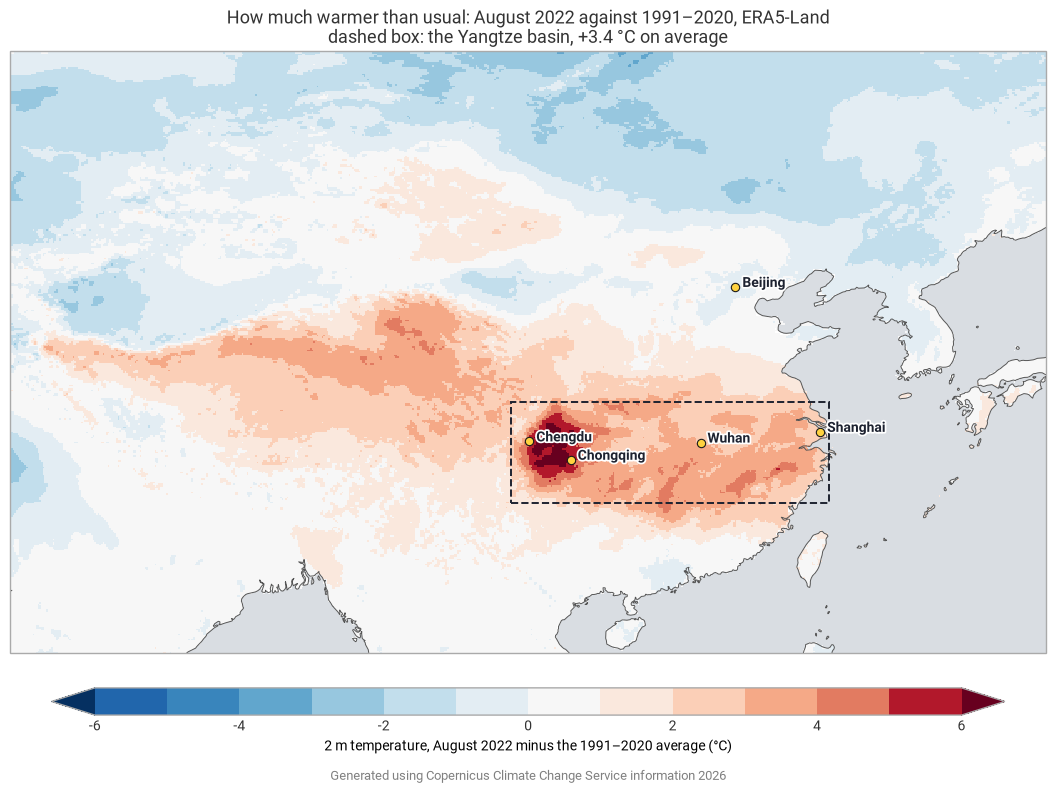

In [6]:
colors = ["#053061", "#2166ac", "#4393c3", "#92c5de", "#d1e5f0", "#f7f7f7", "#f7f7f7",
          "#fddbc7", "#f4a582", "#d6604d", "#b2182b", "#67001f"]
style = ekp.styles.Style(levels=list(range(-6, 7)), colors=colors, extend="both")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], crs=ccrs.PlateCarree(), figsize=(12, 7.5))
chart.ax.add_feature(cfeature.OCEAN, facecolor="#d9dde2", zorder=0)   # ERA5-Land has no sea points
chart.pcolormesh(anom, style=style)
chart.coastlines(linewidth=0.7)                   # coastlines only, no boundaries
chart.ax.add_patch(Rectangle((BOX["west"], BOX["south"]), BOX["east"] - BOX["west"], BOX["north"] - BOX["south"],
                             fill=False, ls="--", lw=1.4, ec="#1d2230", transform=ccrs.PlateCarree(), zorder=9))
label(chart.ax, CITIES)
chart.legend(label=f"2 m temperature, {when} minus the 1991–2020 average (°C)")
chart.title(f"How much warmer than usual: {when} against 1991–2020, ERA5-Land\n"
            f"dashed box: the Yangtze basin, {float(box.mean()):+.1f} °C on average", fontsize=13)
chart.attribution("Generated using Copernicus Climate Change Service information 2026")
chart.save("heat_era5land.png")
chart.show()

## 4 · Your turn 🌍

- **Another summer:** `YEAR = 2013` or `2023`. ERA5-Land monthly means go back to 1950.
- **July instead of August:** `MONTH = "07"`.
- **Rain instead of heat:** `"total_precipitation"` (metres per day) and `100 * this / normal` for a percentage of normal.
- **Somewhere else:** change `AREA` and `BOX`, for example the North China Plain, `dict(north=40, south=34, west=113, east=119)`.

### Data & licence
Copernicus data is free and open under the Copernicus licence (CC-BY 4.0). Credit:
*Generated using Copernicus Climate Change Service information 2026.* ECMWF runs the Copernicus Atmosphere Monitoring Service and the
Copernicus Climate Change Service for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)